![](https://raw.githubusercontent.com/wateraccounting/WaPORMOOC/main/images/banner_notebooks_WaPOR4Global.png)

[![](https://raw.githubusercontent.com//wateraccounting/WaPORMOOC/main/images/colab-badge.png)](https://colab.research.google.com/github/wateraccounting/WaPOR4Global/blob/main/3_Correlation_Analyses/Notebook_3.1_Correlation_Analyses.ipynb?target="_blank")

<div style="text-align:center; margin-top:15px;">
<h3 style="margin-bottom:5px;">
<b>Focus on Agriculture in Erbil</b>
</h3>

<p style="margin-top:5px;">
<b>Notebook 3.1 </b> Correlation Analyses &nbsp; | &nbsp;
<b>Estimated time:</b> 2 hour &nbsp; | &nbsp;
<b>Instructor:</b> Dr. Ahmed Elnaggar
</p>
</div>




### 📚 Course Information

| Item | Description |
|------|-------------|
| **Course** | MOOC — Global Challenges for Water in Agriculture |
| **Module** | 3.2 Correlation analyses |
| **Focus** | Water use, biomass production of cropland in Erbil |
| **Region** | Erbil Governorate, Kurdistan Region of Iraq |
| **Data** | Monthly WaPOR observations (2018-2025) |

---

### 🎯 Learning Objectives

By the end of this notebook, you will be able to:

1. **Compare** AgERA5 and WaPOR precipitation and reference ET data
4. **Evaluate** the correlation between actual water use (AETI), Biomass (NPP) and atmospheric demand (RET), supply (PCP)
3. **Assess** water productivity — how much biomass per unit of water consumed
5. **Identify** the years and seasons where Erbil's agriculture was most stressed

---
> 💡 **Key Question:** *Is water consumption and biomass production in agriculture influenced by the climate?*

---

### 📖 Table of Contents

1. Setup & Data Loading
2. Comparing WaPOR and AgERA5 climate data (PCP and RET)
3. Climatic impact on cropland in Erbil
4. Annual analyses
5. Comparing variables
6. Seasonal analyses
7. What's Next?

---
## ⚙️ 1.  Setup & Data Loading
<p style="margin-top:1px;">
	Some Python packages are required that may not be included in a basic Python installation. Run the cells below to set up your environment.
	</p>

In [30]:
# =============================================================================
# INSTALL & IMPORT PACKAGES
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import os
import warnings
from datetime import datetime

print(f"\n✅ Setup complete — Pandas {pd.__version__}, NumPy {np.__version__}")
print(f"📅 Analysis date: {datetime.now().strftime('%Y-%m-%d')}")


✅ Setup complete — Pandas 2.2.3, NumPy 2.4.6
📅 Analysis date: 2026-11-12


Create folders for where to upload the input data and where to store the results.

In [31]:
# =============================================================================
# CREATE INPUT AND OUTPUT FOLDERS
# =============================================================================

data_folder = 'data'
os.makedirs(data_folder, exist_ok=True)

output_folder = 'output_data'
os.makedirs(output_folder, exist_ok=True)



---
### Input data preparation

Place your WaPOR monthly CSV files in the `data/` folder:

| File | Variable | Description |Section|
|------|----------|-------------|-------|
| `irq_admin1_AgERA5-PCP-M_mm` | PCP* | Monthly precipitation (mm) |1|
| `irq_admin1_AgERA5-RET-M_mm` | RET* | Monthly reference ET (mm) |1|
| `irq_admin1_L1-PCP-M_mm_per_month` | PCP* | Monthly precipitation (mm) |1&2|
| `irq_admin1_L1-RET-M_mm_per_month` | RET* | Monthly reference ET (mm) |1&2|
| `ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month` | AETI** | Monthly actual ET & interception (mm) | 2 |
| `ESA_LC_2021_Erbil_20m_L2-NPP-M_gc_per_m2_per_month` | NPP** | Monthly net primary production (gC/m²) | 2|

**Expected format:**

'* First column = date (`DD/MM/YYYY`), remaining columns = Governorates.

'** First column = date (`DD/MM/YYYY`), remaining columns = land cover classes (.., Grassland, **Cropland**, ..).

📂 Upload your data files

- **Run the cell below** to browse and select your files (you can run it multiple times).  
- **OR drag your files** directly into the `data/` folder in the Files panel (left sidebar).

In [33]:
# =============================================================================
# UPLOAD DATA
# =============================================================================

from google.colab import files
uploaded = files.upload()

# Save each file to the destination folder
for filename, content in uploaded.items():
    dest_path = f'/content/data/{filename}'
    with open(dest_path, 'wb') as f:
        f.write(content)
    print(f" Saved: {dest_path}")

Saving ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv to ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv
Saving ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv to ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv
Saving L1-PCP-M_mm_per_month.csv to L1-PCP-M_mm_per_month.csv
Saving L1-RET-M_mm_per_month.csv to L1-RET-M_mm_per_month.csv
Saving irq_admin1_AgERA5-RET-M_mm.csv to irq_admin1_AgERA5-RET-M_mm.csv
Saving irq_admin1_AgERA5-PCP-M_mm.csv to irq_admin1_AgERA5-PCP-M_mm.csv
 Saved: /content/data/ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv
 Saved: /content/data/ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv
 Saved: /content/data/L1-PCP-M_mm_per_month.csv
 Saved: /content/data/L1-RET-M_mm_per_month.csv
 Saved: /content/data/irq_admin1_AgERA5-RET-M_mm.csv
 Saved: /content/data/irq_admin1_AgERA5-PCP-M_mm.csv


In [34]:
import os

data_folder = "/content/data"

# Rename the two WaPOR climate CSV files
os.rename(
    os.path.join(data_folder, "L1-PCP-M_mm_per_month.csv"),
    os.path.join(data_folder, "irq_admin1_L1-PCP-M_mm_per_month.csv")
)

os.rename(
    os.path.join(data_folder, "L1-RET-M_mm_per_month.csv"),
    os.path.join(data_folder, "irq_admin1_L1-RET-M_mm_per_month.csv")
)

# Display all files
print("Files currently in /content/data:\n")

for filename in sorted(os.listdir(data_folder)):
    print(filename)

Files currently in /content/data:

ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv
ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv
irq_admin1_AgERA5-PCP-M_mm.csv
irq_admin1_AgERA5-RET-M_mm.csv
irq_admin1_L1-PCP-M_mm_per_month.csv
irq_admin1_L1-RET-M_mm_per_month.csv


---
### Create function to read data
We first make a function that reads the information in the files and extracts the information from the right column. For the PCP and RET data, we use the file from Exercise 1 and extract only column **`Erbil`**. For data used in the second part of the Notebook, we extract the data in the column **`40`**, which aligns with the cropland class.  

In [35]:
# =============================================================================
# DATA LOADING — WAPOR MONTHLY (CROPLAND CLASS 40/ OR GOVERNORATE ERBIL)
# =============================================================================

#COL_NAME = '40'   # Land cover class 40 = Cropland OR
#COL_NAME = 'Erbil'

def load_wapor_variable(filepath, var_name, COL_NAME):
    """
    Load a WaPOR monthly CSV and extract the cropland (class 40) column.
    Load a AgERA monthly CSV and extract the governorate (Erbil) column.

    Expected format:
    - First column = date (DD/MM/YYYY or similar)
    - Remaining columns = land cover classes (..., 30, 40, ...) OR governorates (..,Erbil, ...)
    """
    df = pd.read_csv(filepath)
    date_col = df.columns[0]

    # Parse dates
    for fmt in ['%d/%m/%Y', '%m/%d/%Y', '%Y-%m-%d', '%Y/%m/%d']:
        try:
            df[date_col] = pd.to_datetime(df[date_col], format=fmt)
            break
        except (ValueError, TypeError):
            continue
    else:
        df[date_col] = pd.to_datetime(df[date_col], dayfirst=True)

    df.set_index(date_col, inplace=True)
    df.index.name = 'date'
    df = df.sort_index()

    # Find the cropland column (might be int or string)
    col_match = None
    for col in df.columns:
        if str(col).strip() == COL_NAME:
            col_match = col
            break

    if col_match is None:
        raise KeyError(f"Column '{COL_NAME}' not found. Available: {df.columns.tolist()}")

    series = pd.to_numeric(df[col_match], errors='coerce')
    series.name = var_name

    print(f"📄 {var_name}: {len(series)} months | "
          f"{series.index.min().strftime('%b %Y')} — {series.index.max().strftime('%b %Y')} | "
          f"Mean: {series.mean():.2f}")
    return series



---

## 2. Comparing WaPOR and AgERA5 climate data (PCP and RET)
In this section we focus on comparing the climate data from AgERA5 and WaPOR. First we load the PCP and RET data from WaPOR and AgERA5 using the function above.

In [36]:
# =============================================================================
# READ CLIMATE DATA USING FUNCTION AND COMBINE IN SINGLE DATAFRAME
# =============================================================================

print("="*70)
print("LOADING WAPOR AND AgERA5 CLIMATE DATA FOR ERBIL")
print("="*70)

files = {
    'PCP_WaPOR':  os.path.join('/content/data/irq_admin1_L1-PCP-M_mm_per_month.csv'),
    'RET_WaPOR':  os.path.join('/content/data/irq_admin1_L1-RET-M_mm_per_month.csv'),
    'PCP_AgERA5': os.path.join('/content/data/irq_admin1_AgERA5-PCP-M_mm.csv'),
    'RET_AgERA5':  os.path.join('/content/data/irq_admin1_AgERA5-RET-M_mm.csv')
}

series_dict = {}
for var_name, fpath in files.items():
    col_name = 'Erbil'
    if os.path.exists(fpath):
        series_dict[var_name] = load_wapor_variable(fpath, var_name, col_name)
    else:
        raise FileNotFoundError(f"File not found: {fpath}")

# Combine into a single DataFrame
df = pd.DataFrame(series_dict)
df = df.sort_index()

print(f"\n✅ Combined DataFrame: {df.shape[0]} months × {df.shape[1]} variables")
print(f"   Period: {df.index.min().strftime('%b %Y')} — {df.index.max().strftime('%b %Y')}")
print(f"   Missing values: {df.isnull().sum().sum()}")

LOADING WAPOR AND AgERA5 CLIMATE DATA FOR ERBIL
📄 PCP_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 64.51
📄 RET_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 129.19
📄 PCP_AgERA5: 552 months | Jan 1980 — Dec 2025 | Mean: 60.65
📄 RET_AgERA5: 552 months | Jan 1980 — Dec 2025 | Mean: 120.59

✅ Combined DataFrame: 552 months × 4 variables
   Period: Jan 1980 — Dec 2025
   Missing values: 912


The overview indicates a large amount of missing data. What is the source of the missing data?

<details>
  <summary>HINT</summary>

*  Missing data is only from WaPOR, which only has data from 2018-present (period of 1980-2017 is missing)

</details>

Lets calculate the statistics of the dataframe.

In [37]:
# =============================================================================
# INSPECT THE DATA AND CALCULATE STATISTICS
# =============================================================================
print(df)

print("\n📊 Descriptive Statistics:")
display(df.describe().round(2))


            PCP_WaPOR  RET_WaPOR  PCP_AgERA5  RET_AgERA5
date                                                    
1980-01-01        NaN        NaN       91.91       26.40
1980-02-01        NaN        NaN      117.30       37.75
1980-03-01        NaN        NaN      178.85       64.90
1980-04-01        NaN        NaN      165.96      106.75
1980-05-01        NaN        NaN       24.54      169.51
...               ...        ...         ...         ...
2025-08-01       1.27     238.72        0.12      224.05
2025-09-01       0.95     169.86        0.55      162.16
2025-10-01       1.61     112.41        2.62      111.06
2025-11-01      56.27      67.05       61.61       63.21
2025-12-01     180.93      35.30      180.75       33.01

[552 rows x 4 columns]

📊 Descriptive Statistics:


,PCP_WaPOR,RET_WaPOR,PCP_AgERA5,RET_AgERA5
count,96.00,96.00,552.00,552.00
mean,64.51,129.19,60.65,120.59
std,71.39,79.68,64.08,73.29
min,0.69,22.62,0.00,24.42
25%,1.65,49.52,2.66,45.42
50%,46.53,115.04,41.78,109.52
75%,109.43,212.93,105.61,196.29
max,321.96,265.49,301.12,247.39


Lets plot the precipitation data first by running the script as it is. You can see the period where the two datasets overlap. Comment the section "Present all data" out and uncomment the section "Filter for overlapping period where both series have data", and see the results.

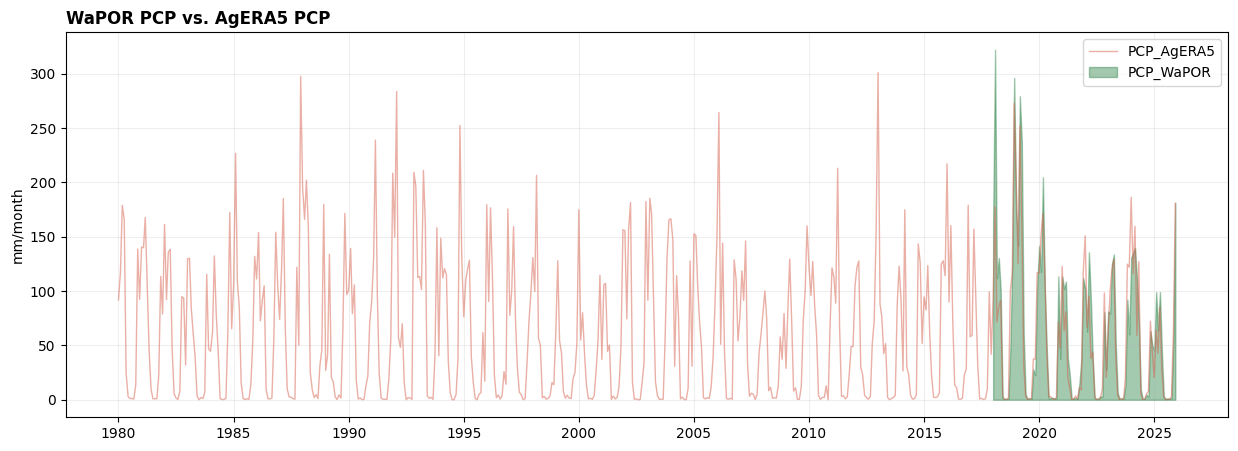

In [38]:
# =============================================================================
# PLOT TWO VARIABLES
# =============================================================================

fig, axes = plt.subplots(1, 1, figsize=(15, 5), sharex=True)

ax = axes

#Present all data
ax.plot(df.index, df['PCP_AgERA5'], color='#d6604d', linewidth=1, alpha=0.5, label='PCP_AgERA5')
ax.fill_between(df.index, 0, df['PCP_WaPOR'], color='#1b7837', alpha=0.4, label='PCP_WaPOR')

#Filter for overlapping period where both series have data
#overlapping_df = df[['PCP_AgERA5', 'PCP_WaPOR']].dropna()
#ax.plot(overlapping_df.index, overlapping_df['PCP_AgERA5'], color='#d6604d', linewidth=1, alpha=0.5, label='PCP_AgERA5')
#ax.fill_between(overlapping_df.index, 0, overlapping_df['PCP_WaPOR'], color='#1b7837', alpha=0.4, label='PCP_WaPOR')

# Adding graphic elements
ax.set_ylabel('mm/month')
ax.set_title('WaPOR PCP vs. AgERA5 PCP', fontweight='bold', loc='left')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.2)

Lets plot the two variables using a scatterplot.

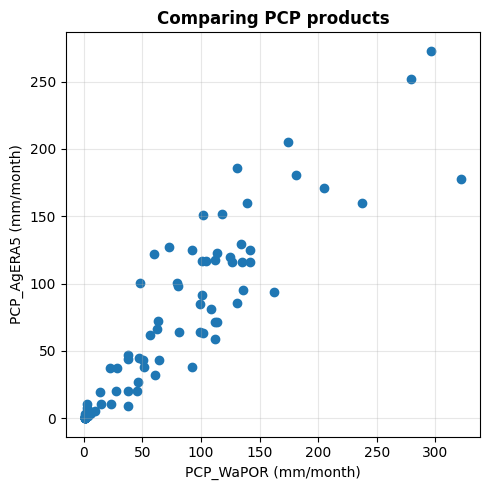

In [39]:
# =============================================================================
# SCATTERPLOT OF TWO VARIABLES
# =============================================================================


fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# Scatter: PCP comparison WaPOR vs AgERA5
ax = axes
ax.scatter(df['PCP_WaPOR'], df['PCP_AgERA5'])

# Adding graphic elements
ax.set_xlabel('PCP_WaPOR (mm/month)')
ax.set_ylabel('PCP_AgERA5 (mm/month)')
ax.set_title('Comparing PCP products', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Lets add the regression line, its slope and intercept and the Coefficient of determination (r<sup>2</sup>).

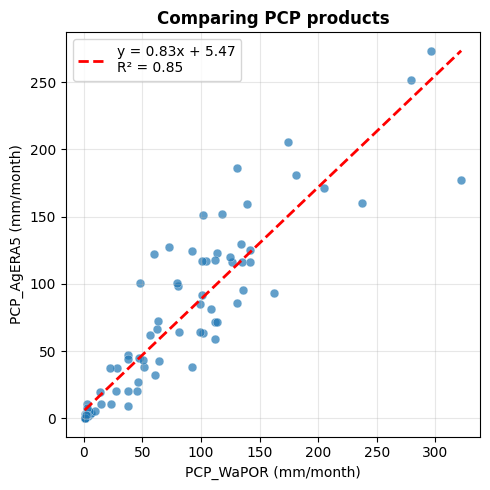

In [40]:
# =============================================================================
# SCATTERPLOT OF TWO VARIABLES
# =============================================================================

fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# Scatter: PCP comparison WaPOR vs AgERA5
ax = axes
ax.scatter(df['PCP_WaPOR'], df['PCP_AgERA5'],
                 s=40, alpha=0.7, edgecolors='white', linewidth=0.3)

# Fit and plot line and add label
mask_valid = df[['PCP_WaPOR', 'PCP_AgERA5']].dropna()
if len(mask_valid) > 2:
    slope, intercept, r, p, se = stats.linregress(mask_valid['PCP_WaPOR'], mask_valid['PCP_AgERA5'])
    x_fit = np.linspace(mask_valid['PCP_WaPOR'].min(), mask_valid['PCP_WaPOR'].max(), 100)
    ax.plot(x_fit, intercept + slope * x_fit, 'r--', linewidth=2,
             label=f'y = {slope:.2f}x + {intercept:.2f}\nR² = {r**2:.2f}')

# Adding graphic elements
ax.set_xlabel('PCP_WaPOR (mm/month)')
ax.set_ylabel('PCP_AgERA5 (mm/month)')
ax.set_title('Comparing PCP products', fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Lets calculate the correlation between the different variables using the `.corr` function.

In [41]:
# =============================================================================
# CALCULATE THE CORRELATION BETWEEN THE VARIABLES IN THE DATAFRAME
# =============================================================================

clim_corr=df.corr()#**2
print(clim_corr.round(2))

            PCP_WaPOR  RET_WaPOR  PCP_AgERA5  RET_AgERA5
PCP_WaPOR        1.00      -0.68        0.92       -0.66
RET_WaPOR       -0.68       1.00       -0.72        1.00
PCP_AgERA5       0.92      -0.72        1.00       -0.72
RET_AgERA5      -0.66       1.00       -0.72        1.00


When comparing the results with what is presented in the scatterplot the values are different. Do you know why?

<details>
  <summary>ANSWER</summary>

*  the function `.corr` calculates the correlation (r), whereas in the scatterplot the r^2 is provided. Uncomment **2 to calculate the square of r.

</details>

---
Lets calculate additional correlation statistics between the AgERA5 and WaPOR Precipitation products.

| Stat | Description |Unit|
|------|----------|-------------|
| r^2 | Coefficient of determination | -|
|RMSE| Root mean square error|mm/month|
| Bias | Bias | mm/month |
| PBias | percentage bias | % |



In [42]:
# =============================================================================
# CALCULATE STATISTICS BETWEEN PCP VARIABLES IN THE DATAFRAME
# =============================================================================

import numpy as np
from sklearn.metrics import mean_squared_error

# Filter for overlapping period where both series have data
comparison_df = df[['PCP_WaPOR', 'PCP_AgERA5']].dropna()

# Ensure there is enough data for comparison
if len(comparison_df) < 2:
    print("Not enough overlapping data for PCP_WaPOR and PCP_AgERA5 to perform comparison.")
else:
    observed = comparison_df['PCP_AgERA5'].values
    predicted = comparison_df['PCP_WaPOR'].values

    # 1. Calculate R-squared (R2) using a direct correlation for consistency with previous R-squared calculation method
    r2 = comparison_df.corr().iloc[0, 1]**2

    # 2. Calculate RMSE using scikit-learn
    rmse = np.sqrt(mean_squared_error(observed, predicted))

    # 3. Calculate Bias
    bias = np.mean(predicted - observed)

    # 4. Calculate Percentage Bias (PBIAS)
    sum_diff = np.sum(predicted - observed)
    sum_observed = np.sum(observed)

    if sum_observed != 0:
        pbias = (sum_diff / sum_observed) * 100
    else:
        pbias = np.nan # Avoid division by zero

    print(f"Comparison of PCP_WaPOR (predicted) and PCP_AgERA5 (observed) (N={len(comparison_df)}):")
    print(f"  R-squared (R2): {r2:.2f}")
    print(f"  RMSE: {rmse:.2f} mm/month")
    print(f"  Bias: {bias:.2f} mm/month")
    print(f"  Percentage Bias (PBIAS): {pbias:.2f} %")


Comparison of PCP_WaPOR (predicted) and PCP_AgERA5 (observed) (N=96):
  R-squared (R2): 0.85
  RMSE: 28.25 mm/month
  Bias: 5.38 mm/month
  Percentage Bias (PBIAS): 9.09 %


Repeat the analyses for RET and answer the following questions:

- What is the regression line between the two RET products?
- What are the correlation statistics (R^2, RMSE, Bias and Percentage bias) when comparing the two RET products?


In [44]:
import numpy as np
from scipy.stats import linregress
from sklearn.metrics import mean_squared_error, r2_score

# Select the overlapping RET observations
ret_data = df[["RET_WaPOR", "RET_AgERA5"]].dropna()

# Predicted and observed values
predicted = ret_data["RET_WaPOR"].values
observed = ret_data["RET_AgERA5"].values

# Linear regression: predicted = slope * observed + intercept
slope, intercept, r_value, p_value, std_err = linregress(
    observed, predicted
)

# Calculate performance statistics
r2 = r2_score(observed, predicted)
rmse = np.sqrt(mean_squared_error(observed, predicted))
bias = np.mean(predicted - observed)
pbias = (np.sum(predicted - observed) / np.sum(observed)) * 100

# Display results
print("RET_WaPOR (predicted) vs RET_AgERA5 (observed)")
print(f"Number of observations (N): {len(ret_data)}")

print("\nRegression equation:")
print(f"RET_WaPOR = {slope:.4f} × RET_AgERA5 + {intercept:.4f}")

print("\nCorrelation and performance statistics:")
print(f"R-squared (R2): {r2:.4f}")
print(f"RMSE: {rmse:.2f} mm/month")
print(f"Bias: {bias:.2f} mm/month")
print(f"Percentage Bias (PBIAS): {pbias:.2f} %")

RET_WaPOR (predicted) vs RET_AgERA5 (observed)
Number of observations (N): 96

Regression equation:
RET_WaPOR = 1.0761 × RET_AgERA5 + -4.9188

Correlation and performance statistics:
R-squared (R2): 0.9847
RMSE: 9.08 mm/month
Bias: 4.57 mm/month
Percentage Bias (PBIAS): 3.67 %


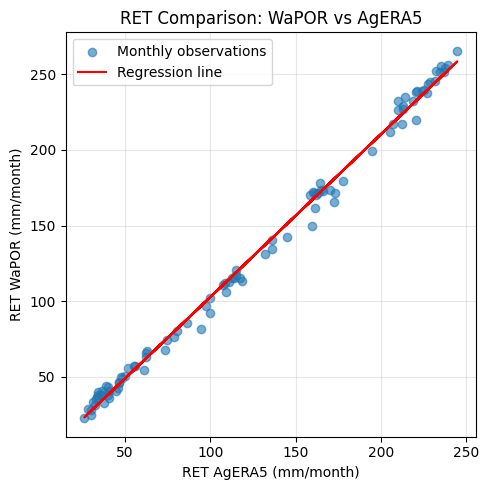

In [45]:
# =============================================================================
# SCATTERPLOT OF TWO VARIABLES
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

# Scatter: RET comparison WaPOR vs AgERA5
ax.scatter(
    df_common["RET_AgERA5"],
    df_common["RET_WaPOR"],
    alpha=0.6,
    label="Monthly observations"
)

# Add regression line
x = df_common["RET_AgERA5"].dropna()
y = df_common.loc[x.index, "RET_WaPOR"]

slope, intercept = np.polyfit(x, y, 1)

ax.plot(
    x,
    slope * x + intercept,
    color="red",
    label="Regression line"
)

# Add labels and title
ax.set_xlabel("RET AgERA5 (mm/month)")
ax.set_ylabel("RET WaPOR (mm/month)")
ax.set_title("RET Comparison: WaPOR vs AgERA5")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### ✍ Conclusion
Advantage of AgERA5 is the long time series, both data sets can be accessed using the WaPOR download API and have the same data format structure. For the next part we will be using the WaPOR data to compare to the AETI and NPP for croplands in Erbil.  



---

## 3. Climatic impact on cropland in Erbil

In this section we further dive into croplands in Erbil to evaluate the impact of the climate drivers (PCP and RET) on agricultural water use (AETI) and crop production (NPP).

In addition to the WaPOR PCP and RET, we use the WaPOR AETI and NPP monthly time series, extracted for **cropland** areas (Land Cover Class 40) within Erbil Governorate.

**Overview of the Variables used in this section:**

| Variable | Full Name | Unit | What It Tells Us |
|----------|-----------|------|-----------------|
| **WaPOR_PCP** | Precipitation | mm/month | 🌧️ Water **supply** — how much rain falls |
| **WaPOR_RET** | Reference Evapotranspiration | mm/month | ☀️ Atmospheric **demand** — how much water the atmosphere wants |
| **WaPOR_AETI** | Actual Evapotranspiration & Interception | mm/month | 💧 Actual water **consumption** by crops and soil |
| **WaPOR_NPP** | Net Primary Production | gC/m²/month | 🌱 Biomass **production** — photosynthetic output |


In this section we will explore the following relationships:

- **PCP vs AETI** → Is actual water use exceeding rainfall? (irrigation dependency)
- **RET vs AETI** → How much of the demand is actually met? (indicator of stress)
- **NPP / AETI** → **Water productivity** — biomass produced per mm of water consumed

Before running the codes, ensure that you have uploaded the following files in the `data/` folder:

| File | Variable | Description |
|------|----------|-------------|
| `irq_admin1_L1-PCP-M_mm_per_month` | PCP* | Monthly precipitation (mm) |
| `irq_admin1_L1-RET-M_mm_per_month` | RET* | Monthly reference ET (mm) |
| `ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month` | AETI** | Monthly actual ET & interception (mm) |
| `ESA_LC_2021_Erbil_20m_L2-NPP-M_gc_per_m2_per_month` | NPP** | Monthly net primary production (gC/m²) |

In [46]:
import os
import pandas as pd

data_folder = "/content/data"

required_files = [
    "irq_admin1_L1-PCP-M_mm_per_month.csv",
    "irq_admin1_L1-RET-M_mm_per_month.csv",
    "ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv",
    "ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv"
]

for filename in required_files:
    filepath = os.path.join(data_folder, filename)

    print("\n" + "=" * 65)
    print(filename)

    if os.path.exists(filepath):
        data = pd.read_csv(filepath, index_col=0, parse_dates=True)

        print("Status: FOUND")
        print("Dimensions:", data.shape)
        print("Date range:", data.index.min(), "to", data.index.max())
        print("Columns:", data.columns.tolist())
        print("Missing values:", data.isna().sum().sum())

        display(data.head(3))

    else:
        print("Status: FILE NOT FOUND")


irq_admin1_L1-PCP-M_mm_per_month.csv
Status: FOUND
Dimensions: (96, 18)
Date range: 2018-01-01 00:00:00 to 2025-12-01 00:00:00
Columns: ['Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']
Missing values: 0


,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
2018-01-01,8.44,0.02,0.00,0.08,0.53,151.77,0.65,4.19,13.41,148.86,162.52,0.09,60.23,1.50,66.17,18.34,0.09,2.53
2018-02-01,67.24,48.96,45.82,52.41,63.57,443.43,77.47,99.97,178.15,284.76,321.96,64.26,216.28,77.75,184.78,154.68,58.85,96.92
2018-03-01,14.14,7.28,2.72,3.94,3.04,81.12,10.84,16.40,20.92,125.01,111.83,11.28,48.08,9.03,55.00,23.16,3.13,11.30



irq_admin1_L1-RET-M_mm_per_month.csv
Status: FOUND
Dimensions: (96, 18)
Date range: 2018-01-01 00:00:00 to 2025-12-01 00:00:00
Columns: ['Al-Anbar', 'Al-Basrah', 'Al-Muthanna', 'Al-Najaf', 'Al-Qadissiya', 'Al-Sulaymaniyah', 'Babil', 'Baghdad', 'Diyala', 'Duhok', 'Erbil', 'Kerbala', 'Kirkuk', 'Maysan', 'Ninewa', 'Salah Al-Din', 'Thi Qar', 'Wassit']
Missing values: 0


,Al-Anbar,Al-Basrah,Al-Muthanna,Al-Najaf,Al-Qadissiya,Al-Sulaymaniyah,Babil,Baghdad,Diyala,Duhok,Erbil,Kerbala,Kirkuk,Maysan,Ninewa,Salah Al-Din,Thi Qar,Wassit
2018-01-01,61.05,91.16,88.65,76.06,78.36,33.93,69.96,63.28,67.90,27.94,32.96,66.98,53.16,86.16,40.62,57.19,84.35,79.50
2018-02-01,68.49,105.48,105.52,87.20,87.15,37.70,76.49,68.96,68.65,37.61,37.74,73.52,49.86,93.32,46.94,58.43,98.13,84.33
2018-03-01,147.44,184.18,188.29,169.65,174.23,81.49,152.74,139.84,143.00,77.13,81.33,154.50,107.34,180.06,102.05,128.25,186.98,172.84



ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv
Status: FOUND
Dimensions: (96, 8)
Date range: 2018-01-01 00:00:00 to 2025-12-01 00:00:00
Columns: ['10', '20', '30', '40', '50', '60', '80', '90']
Missing values: 0


,10,20,30,40,50,60,80,90
2018-01-01,3.84,5.23,4.05,7.74,5.53,4.21,32.02,9.3
2018-02-01,8.13,7.71,7.76,13.20,7.16,6.25,36.96,10.4
2018-03-01,36.16,33.35,30.89,46.42,21.82,20.10,88.62,34.4



ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv
Status: FOUND
Dimensions: (96, 8)
Date range: 2018-01-01 00:00:00 to 2025-12-01 00:00:00
Columns: ['10', '20', '30', '40', '50', '60', '80', '90']
Missing values: 0


,10,20,30,40,50,60,80,90
2018-01-01,6.03,7.36,5.69,9.31,2.62,2.42,3.81,9.61
2018-02-01,10.30,11.69,9.82,17.23,4.50,4.50,6.19,11.45
2018-03-01,41.20,44.03,35.17,54.47,14.18,13.90,19.29,31.41


The following cell reads the uploaded .csv files and extracts the correct column (Erbil for the climatic data and cropland `40` for the agricultural data). It creates a new data frame `df2` with the data.

In [48]:
# =============================================================================
# READ CLIMATE DATA USING FUNCTION AND COMBINE IN SINGLE DATAFRAME
# =============================================================================

files = {
    'PCP_WaPOR': os.path.join('/content/data/irq_admin1_L1-PCP-M_mm_per_month.csv'),
    'RET_WaPOR': os.path.join('/content/data/irq_admin1_L1-RET-M_mm_per_month.csv'),
    'AETI_WaPOR': os.path.join('/content/data/ESA_LC_2021_Erbil_20m_L2-AETI-M_mm_per_month.csv'),
    'NPP_WaPOR': os.path.join('/content/data/ESA_LC_2021_Erbil_20m_L2-NPP-M_gC_per_m2_per_month.csv')
}

series_dict = {}

for var_name, fpath in files.items():

    # Erbil governorate for climate variables;
    # ESA class 40 represents Cropland
    col_name = '40' if 'AETI' in var_name or 'NPP' in var_name else 'Erbil'

    if os.path.exists(fpath):
        series_dict[var_name] = load_wapor_variable(
            fpath, var_name, col_name
        )
    else:
        raise FileNotFoundError(f"File not found: {fpath}")

# Combine into a single DataFrame
df2 = pd.DataFrame(series_dict)
df2 = df2.sort_index()

print(f"\nCombined DataFrame: {df2.shape[0]} months × {df2.shape[1]} variables")
print(f"Period: {df2.index.min().strftime('%b %Y')} — {df2.index.max().strftime('%b %Y')}")
print(f"Missing values: {df2.isnull().sum().sum()}")

display(df2.head())

📄 PCP_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 64.51
📄 RET_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 129.19
📄 AETI_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 27.59
📄 NPP_WaPOR: 96 months | Jan 2018 — Dec 2025 | Mean: 21.29

Combined DataFrame: 96 months × 4 variables
Period: Jan 2018 — Dec 2025
Missing values: 0


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
date,,,,
2018-01-01,162.52,32.96,7.74,9.31
2018-02-01,321.96,37.74,13.20,17.23
2018-03-01,111.83,81.33,46.42,54.47
2018-04-01,130.45,113.67,51.90,62.13
2018-05-01,100.58,149.57,39.99,30.06


In [49]:
# =============================================================================
# INSPECT THE DATA AND CALCULATE STATISTICS
# =============================================================================

print(df2)

print("\n📊 Descriptive Statistics:")
display(df2.describe().round(2))


            PCP_WaPOR  RET_WaPOR  AETI_WaPOR  NPP_WaPOR
date                                                   
2018-01-01     162.52      32.96        7.74       9.31
2018-02-01     321.96      37.74       13.20      17.23
2018-03-01     111.83      81.33       46.42      54.47
2018-04-01     130.45     113.67       51.90      62.13
2018-05-01     100.58     149.57       39.99      30.06
...               ...        ...         ...        ...
2025-08-01       1.27     238.72       20.12       1.16
2025-09-01       0.95     169.86       21.38       4.45
2025-10-01       1.61     112.41       16.64       7.49
2025-11-01      56.27      67.05        8.94       7.31
2025-12-01     180.93      35.30        4.44       4.42

[96 rows x 4 columns]

📊 Descriptive Statistics:


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
count,96.00,96.00,96.00,96.00
mean,64.51,129.19,27.59,21.29
std,71.39,79.68,21.21,28.34
min,0.69,22.62,4.44,0.82
25%,1.65,49.52,12.90,3.65
50%,46.53,115.04,20.96,7.28
75%,109.43,212.93,34.98,27.41
max,321.96,265.49,104.38,121.72


Let's plot the dataframe using the `.plot` function and add the legend. To plot only a selection of the variables, run the second line in the cell below.

Notice that if you put 'legend' as 'True' you get a legend in the figure.

<Axes: xlabel='date'>

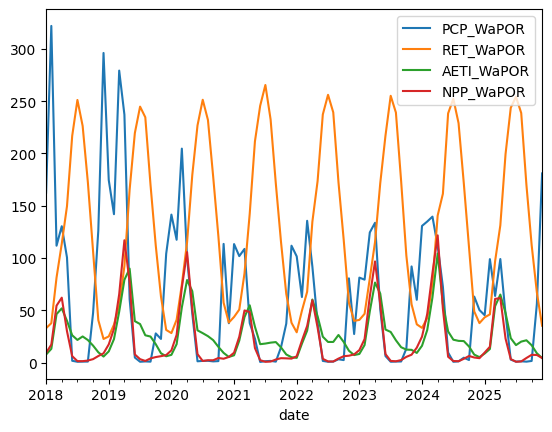

In [50]:
# =============================================================================
# VISUALISE THE TIMESERIES
# =============================================================================

df2.plot(legend=True, xlabel='date')
#df2[['PCP_WaPOR', 'AETI_WaPOR']].plot(legend=True)

---
## 4. Annual analyses

Lets have a look at the data first and generate the annual values and add then to a data frame.

In [51]:
# =============================================================================
# GENERATE ANNUAL TIMESERIES
# =============================================================================

annual_pcp = df2['PCP_WaPOR'].resample('YE').sum()
annual_ret = df2['RET_WaPOR'].resample('YE').sum()
annual_aeti = df2['AETI_WaPOR'].resample('YE').sum()
annual_npp = df2['NPP_WaPOR'].resample('YE').sum()

annual_summary = pd.DataFrame({
    'Annual PCP (mm/year)': annual_pcp,
    'Annual RET (mm/year)': annual_ret,
    'Annual AETI (mm/year)': annual_aeti,
    'Annual NPP (mm/year)': annual_npp
})

display(annual_summary)


,Annual PCP (mm/year),Annual RET (mm/year),Annual AETI (mm/year),Annual NPP (mm/year)
date,,,,
2018-12-31,1301.93,1451.64,285.79,202.91
2019-12-31,1055.93,1449.77,411.58,344.58
2020-12-31,769.67,1542.72,361.17,294.96
2021-12-31,553.37,1667.51,263.14,165.96
2022-12-31,547.10,1574.67,287.31,186.04
2023-12-31,644.80,1534.49,347.94,291.38
2024-12-31,721.81,1542.72,391.64,357.98
2025-12-31,598.41,1638.64,299.97,199.63


Lets calculate if there was sufficient rainfall to account for the water consumption of the crops by calculating the difference and adding the results to the data frame.

In [52]:
# =============================================================================
# CALCULATE PCP-AETI
# =============================================================================

annual_summary['Annual (PCP-AETI) (mm/year)'] = annual_summary['Annual PCP (mm/year)'] - annual_summary['Annual AETI (mm/year)']
display(annual_summary.round(2))

,Annual PCP (mm/year),Annual RET (mm/year),Annual AETI (mm/year),Annual NPP (mm/year),Annual (PCP-AETI) (mm/year)
date,,,,,
2018-12-31,1301.93,1451.64,285.79,202.91,1016.14
2019-12-31,1055.93,1449.77,411.58,344.58,644.35
2020-12-31,769.67,1542.72,361.17,294.96,408.50
2021-12-31,553.37,1667.51,263.14,165.96,290.23
2022-12-31,547.10,1574.67,287.31,186.04,259.79
2023-12-31,644.80,1534.49,347.94,291.38,296.86
2024-12-31,721.81,1542.72,391.64,357.98,330.17
2025-12-31,598.41,1638.64,299.97,199.63,298.44


In [73]:
# =============================================================================
# IDENTIFY THE HIGHEST R² CORRELATION
# =============================================================================

import numpy as np

# Calculate R² for both seasons
summer_r2 = summer_correlation ** 2
winter_r2 = winter_correlation ** 2

# Exclude self-correlations (diagonal values)
np.fill_diagonal(summer_r2.values, np.nan)
np.fill_diagonal(winter_r2.values, np.nan)

# Find the highest R² for each season
summer_max = summer_r2.stack().idxmax()
winter_max = winter_r2.stack().idxmax()

# Display results
print("SUMMER SEASON")
print("Variables:", summer_max[0], "and", summer_max[1])
print("Highest R²:", round(summer_r2.loc[summer_max[0], summer_max[1]], 4))

print("\nWINTER SEASON")
print("Variables:", winter_max[0], "and", winter_max[1])
print("Highest R²:", round(winter_r2.loc[winter_max[0], winter_max[1]], 4))

SUMMER SEASON
Variables: AETI_WaPOR and NPP_WaPOR
Highest R²: 0.7329

WINTER SEASON
Variables: AETI_WaPOR and NPP_WaPOR
Highest R²: 0.9759


In [74]:
# =============================================================================
# FIND THE HIGHEST R² CORRELATION IN THE FULL DATASET
# =============================================================================

import numpy as np

# Calculate Pearson correlation matrix from all monthly observations
correlation_matrix = df2.corr(method='pearson')

# Square correlations to obtain R²
r2_matrix = correlation_matrix ** 2

# Exclude correlations of variables with themselves
np.fill_diagonal(r2_matrix.values, np.nan)

# Identify the highest R² value
highest_pair = r2_matrix.stack().idxmax()
highest_value = r2_matrix.stack().max()

print("Highest R² correlation:")
print("Variable 1:", highest_pair[0])
print("Variable 2:", highest_pair[1])
print("R² value:", round(highest_value, 4))

Highest R² correlation:
Variable 1: AETI_WaPOR
Variable 2: NPP_WaPOR
R² value: 0.7676


Note that all years the annual precipitation exceeds the agricultural water consumption.

Repeat the steps and calculate the difference between the climatic water demand (RET) and the actual water use (AETI) for each year.

 🔔 **QUIZ**: Which year had the highest deficit (RET-AETI)? and how much is this deficit in mm/year (no digits). Note down your answer you need it for the quiz!!

---
Now lets plot the annual values of each variable using one code using `plt.subplots`

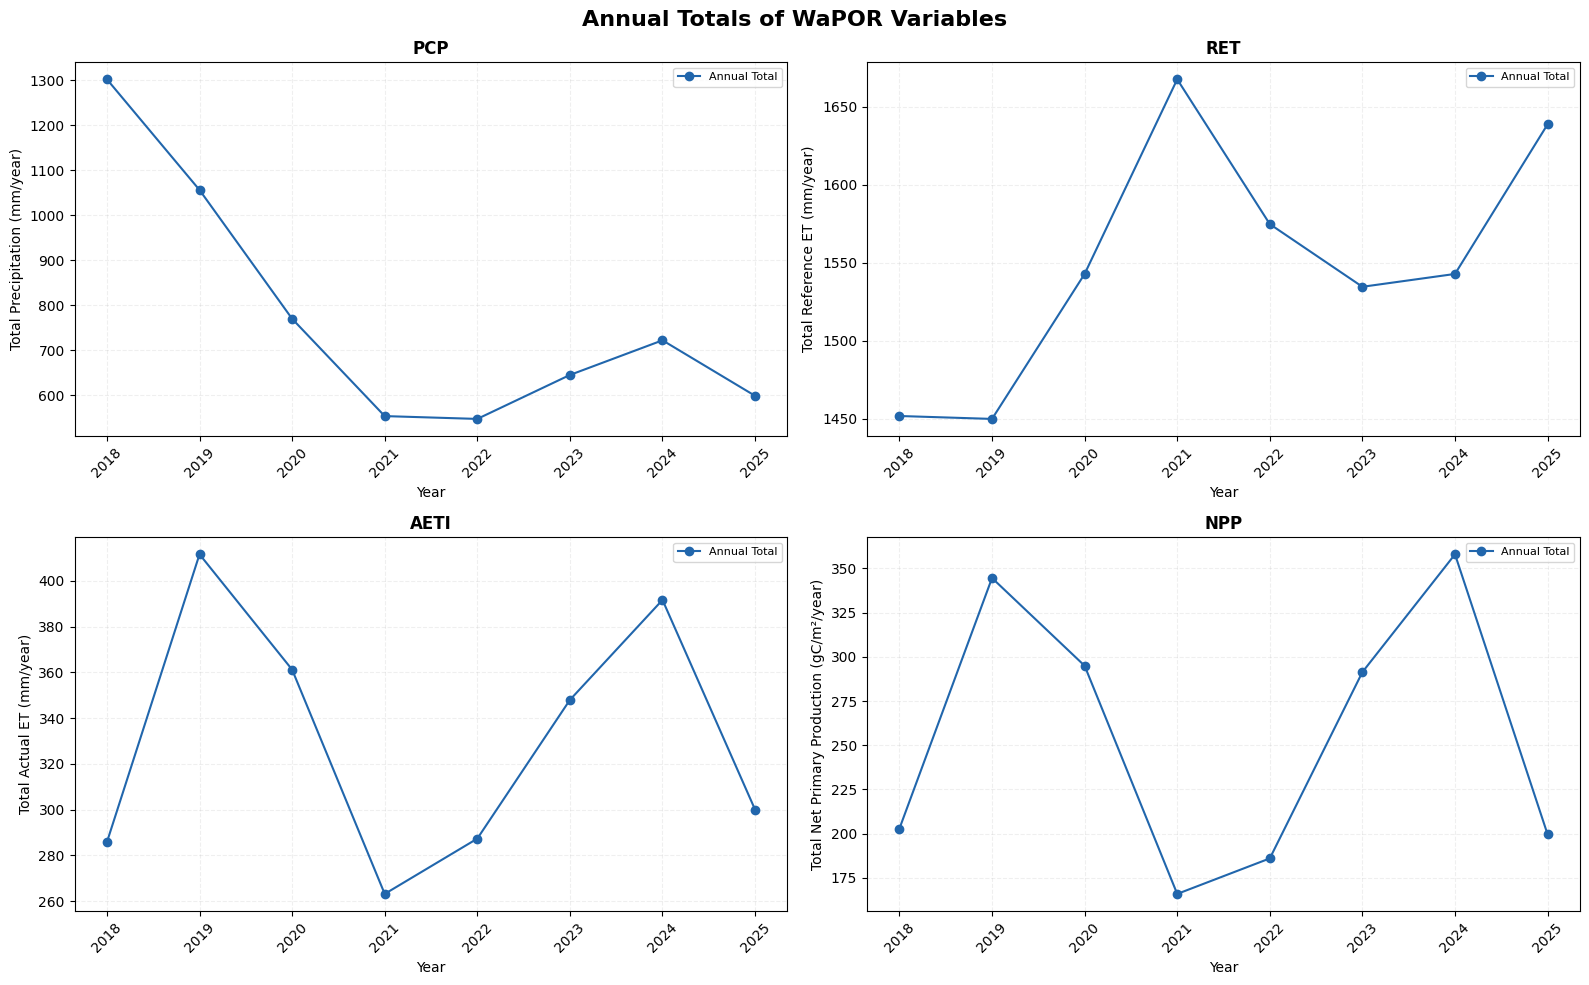

In [53]:
# =============================================================================
# ANNUAL COMPARISON
# =============================================================================

# Extract the years from the DataFrame index for plotting
years = annual_summary.index.year

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Annual Totals of WaPOR Variables', fontsize=16, fontweight='bold') # Changed suptitle

variables = ['Annual PCP (mm/year)', 'Annual RET (mm/year)', 'Annual AETI (mm/year)', 'Annual NPP (mm/year)']
y_labels = {
    'Annual PCP (mm/year)': 'Total Precipitation (mm/year)',
    'Annual RET (mm/year)': 'Total Reference ET (mm/year)',
    'Annual AETI (mm/year)': 'Total Actual ET (mm/year)',
    'Annual NPP (mm/year)': 'Total Net Primary Production (gC/m²/year)'
}

for idx, var in enumerate(variables):
    row, col = divmod(idx, 2)
    ax = axes[row, col]

    # Plot using the extracted years and the corresponding column from annual_summary_df
    ax.plot(years, annual_summary[var], marker='o', linestyle='-', label='Annual Total', color='#2166ac') # Changed label

    ax.set_title(var.replace(" (mm/year)", "").replace(" (gC/m²)", "").replace("Annual ", ""), fontsize=12, fontweight='bold') # Adjusted title formatting
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel(y_labels[var], fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.2)
    ax.set_xticks(years) # Set x-ticks to display all years
    ax.tick_params(axis='x', rotation=45) # Rotate x-axis labels for readability

plt.tight_layout()
plt.show()

🔔 **Discuss:** Based the timeseries available in WaPOR (2018-2025), which year is the wettest and which year is the driest? Taking into consideration RET (by calculating PCP-RET) is the same year still the driest? Did the climatic variables in all years have the same impact on agricultural water consumption and biomass production?

---

Lets create a summary table with all the variables, some additional calculations and save it as a csv file.

In [54]:
# =============================================================================
# ANNUAL SUMMARY TABLE
# =============================================================================

annual_summary = pd.DataFrame()
annual_summary['PCP (mm)']  = df2.resample('YE')['PCP_WaPOR'].sum()
annual_summary['RET (mm)']  = df2.resample('YE')['RET_WaPOR'].sum()
annual_summary['AETI (mm)'] = df2.resample('YE')['AETI_WaPOR'].sum()
annual_summary['NPP (gC/m²)'] = df2.resample('YE')['NPP_WaPOR'].sum()
annual_summary['PCP-AETI (mm)'] = annual_summary['PCP (mm)'] - annual_summary['AETI (mm)']
annual_summary['PCP-RET (mm)'] = annual_summary['PCP (mm)'] - annual_summary['RET (mm)']
annual_summary['AETI/RET']  = annual_summary['AETI (mm)'] / annual_summary['RET (mm)']
annual_summary['WP (gC/mm)'] = annual_summary['NPP (gC/m²)'] / annual_summary['AETI (mm)']

annual_summary.index = annual_summary.index.year
annual_summary.index.name = 'Year'

print("="*90)
print("ANNUAL SUMMARY — ERBIL CROPLAND")
print("="*90)
display(annual_summary.round(1))

# Save
annual_summary.to_csv(os.path.join(output_folder, 'erbil_cropland_annual_summary.csv'))
print("\n✅ Saved to output_data/erbil_cropland_annual_summary.csv")

ANNUAL SUMMARY — ERBIL CROPLAND


,PCP (mm),RET (mm),AETI (mm),NPP (gC/m²),PCP-AETI (mm),PCP-RET (mm),AETI/RET,WP (gC/mm)
Year,,,,,,,,
2018,1301.9,1451.6,285.8,202.9,1016.1,-149.7,0.2,0.7
2019,1055.9,1449.8,411.6,344.6,644.4,-393.8,0.3,0.8
2020,769.7,1542.7,361.2,295.0,408.5,-773.1,0.2,0.8
2021,553.4,1667.5,263.1,166.0,290.2,-1114.1,0.2,0.6
2022,547.1,1574.7,287.3,186.0,259.8,-1027.6,0.2,0.6
2023,644.8,1534.5,347.9,291.4,296.9,-889.7,0.2,0.8
2024,721.8,1542.7,391.6,358.0,330.2,-820.9,0.3,0.9
2025,598.4,1638.6,300.0,199.6,298.4,-1040.2,0.2,0.7



✅ Saved to output_data/erbil_cropland_annual_summary.csv


Lets interrogate the new dataframe and report the results  

In [55]:
# =============================================================================
# IDENTIFY EXTREMES
# =============================================================================

driest_yr   = annual_summary['PCP (mm)'].idxmin()
wettest_yr  = annual_summary['PCP (mm)'].idxmax()
best_wp_yr  = annual_summary['WP (gC/mm)'].idxmax()
worst_wp_yr = annual_summary['WP (gC/mm)'].idxmin()

print(f"💡 Year Rankings:")
print(f"   Driest:  {driest_yr} ({annual_summary.loc[driest_yr, 'PCP (mm)']:.0f} mm rainfall)")
print(f"   Wettest: {wettest_yr} ({annual_summary.loc[wettest_yr, 'PCP (mm)']:.0f} mm rainfall)")
print(f"   Most productive:  {best_wp_yr} (WP = {annual_summary.loc[best_wp_yr, 'WP (gC/mm)']:.2f})")
print(f"   Least productive: {worst_wp_yr} (WP = {annual_summary.loc[worst_wp_yr, 'WP (gC/mm)']:.2f})")

💡 Year Rankings:
   Driest:  2022 (547 mm rainfall)
   Wettest: 2018 (1302 mm rainfall)
   Most productive:  2024 (WP = 0.91)
   Least productive: 2021 (WP = 0.63)


---
## 5. Comparing variables

Calculate the correlation beween variables in the dataframe.

In [56]:
# =============================================================================
# CALCULATE CORRELATION BETWEEN VARIABLES IN DATAFRAME
# =============================================================================

corr = df2.corr()**2
print(corr.round(2))


            PCP_WaPOR  RET_WaPOR  AETI_WaPOR  NPP_WaPOR
PCP_WaPOR        1.00       0.47        0.02       0.25
RET_WaPOR        0.47       1.00        0.05       0.04
AETI_WaPOR       0.02       0.05        1.00       0.77
NPP_WaPOR        0.25       0.04        0.77       1.00


🔔 **QUIZ**: Which variables have the highest correlation? and what is the correlation?

- Note down the answer you need it for the quiz!

- Why are we not calculating the RMSE and Bias?

---
From the correlation calculation, the precipitation and AETI do not have a good correlation, indicating that the water consumption in the croplands are not dependent on rainfall. Lets plot the two variables against each other (create a scatterplot for PCP vs AETI), including statistics and linear regression in the graph.

If you follow the instructions indicate by a ▶ you add a coloring of the points to indicate which months each data point is generated from.  

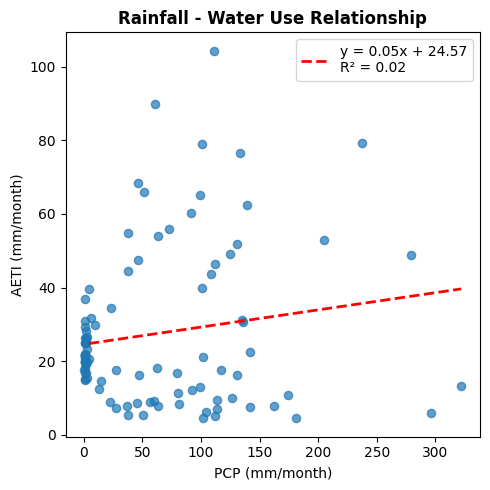

In [57]:
# =============================================================================
# SCATTERPLOT OF TWO VARIABLES
# =============================================================================

fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# Scatter: AETI vs PCP
ax = axes
sc = ax.scatter(df2['PCP_WaPOR'], df2['AETI_WaPOR'], s=35, alpha=0.7)
# ▶ Comment the line above out and replace it with the one below
# sc = ax.scatter(df2['PCP_WaPOR'], df2['AETI_WaPOR'],c=df2.index.month,cmap='twilight', s=35, alpha=0.7)

# Fit line & display statistics
slope, intercept, r, p, se = stats.linregress(df2['PCP_WaPOR'], df2['AETI_WaPOR'])
x_fit = np.linspace(df2['AETI_WaPOR'].min(), df2['PCP_WaPOR'].max(), 100)
ax.plot(x_fit, intercept + slope * x_fit, 'r--', linewidth=2,label=f'y = {slope:.2f}x + {intercept:.2f}\nR² = {r**2:.2f}')

ax.set_xlabel('PCP (mm/month)')
ax.set_ylabel('AETI (mm/month)')
ax.set_title('Rainfall - Water Use Relationship', fontweight='bold')
ax.legend()

# Add a colorbar for the month
# plt.colorbar(sc, ax=ax, label='Month')
# ▶ Uncomment the line above to add the legend colorbar

plt.tight_layout()
plt.show()

It is clear that there are two different periods in the year where AETI is responding differently to increase in PCP. In the winter months (November to February) there is high precipitation and low water consumption, compared to the summer months where AETI is high compared to low or zero precipitation. This illustrates that there are other sources of water during the summer months, whereas during the winter months, the limiting factor is the atmospheric water demand. Lets illustrate this by having a closer look at the timeseries and highlight when AETI exceeds PCP.

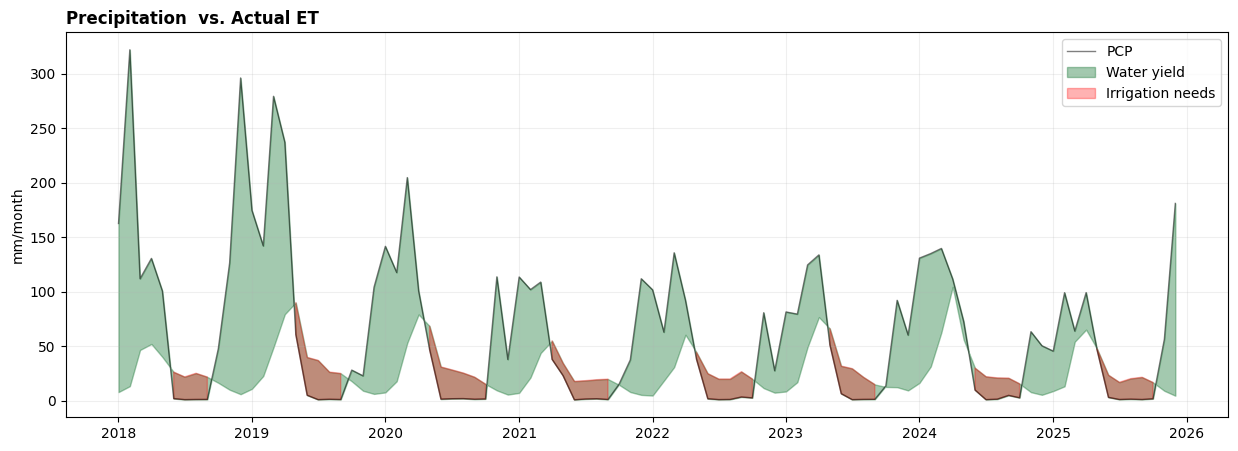

In [58]:
# =============================================================================
# Irrigation needs — AETI / PCP
# =============================================================================

fig, axes = plt.subplots(1, 1, figsize=(15, 5), sharex=True)

# --- AETI vs PCP ---
ax = axes
ax.plot(df2.index, df2['PCP_WaPOR'], color='black', linewidth=1, alpha=0.5, label='PCP')
ax.fill_between(df2.index, df2['PCP_WaPOR'], df2['AETI_WaPOR'], color='#1b7837', alpha=0.4, label='Water yield')

# Shade the gap (irrigation needs)
ax.fill_between(df2.index, df2['AETI_WaPOR'], df2['PCP_WaPOR'],
                 where=df2['PCP_WaPOR'] < df2['AETI_WaPOR'],
                 color='red', alpha=0.3, label='Irrigation needs')
ax.set_ylabel('mm/month')
ax.set_title('Precipitation  vs. Actual ET', fontweight='bold', loc='left')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.2)


Lets calculate the annual irrigation needs, during those months where PCP is less than AETI.

The results are different from the earlier calculations and shows a deficit, what is the reason for this?

<details>
<summary>ANSWER</summary>
The calculation using the annual data incorporates the surplus during the rainy season, whereas this calculation only considers the months where there is a deficit.
</details>

🔔 **Quiz question**:

Which year had the largest irrigation need?

In [59]:
# =============================================================================
# CALCULATE ANNUAL IRRIGATION NEEDS
# =============================================================================

monthly_PCP_AETI_difference = df2.loc[df2['PCP_WaPOR'] < df2['AETI_WaPOR'], ['PCP_WaPOR', 'AETI_WaPOR']].apply(lambda x: x['PCP_WaPOR'] - x['AETI_WaPOR'], axis=1)
annual_PCP_AETI_difference = monthly_PCP_AETI_difference.resample('YE').sum()

#print("Difference (PCP - AETI) for months where PCP < AETI:")
#print(monthly_PCP_AETI_difference)
print("Annual Difference (PCP - AETI):")
print(annual_PCP_AETI_difference)


Annual Difference (PCP - AETI):
date
2018-12-31    -89.92
2019-12-31   -149.16
2020-12-31   -135.23
2021-12-31    -98.45
2022-12-31   -107.76
2023-12-31   -102.74
2024-12-31    -89.68
2025-12-31    -91.73
Freq: YE-DEC, dtype: float64


Repeat the analyses using RET and AETI and answer the following questions:

- The slope between RET and AETI is highest in the summer or winter season?
- The deficit between climatic demand (RET) and actual water use (AETI) is largest in which year?


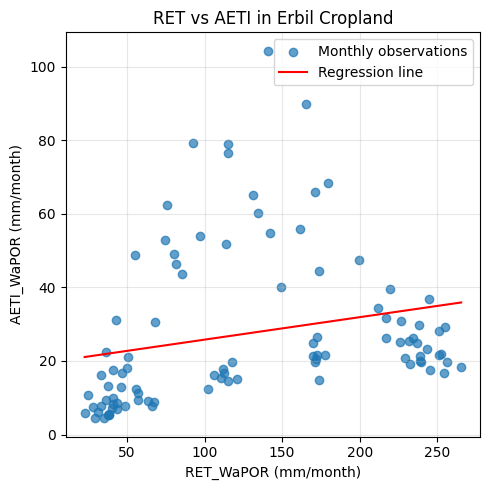

Regression equation: AETI = 0.0611 × RET + 19.6980


In [61]:
# =============================================================================
# SCATTERPLOT: RET vs AETI
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

# Scatterplot
ax.scatter(
    df2["RET_WaPOR"],
    df2["AETI_WaPOR"],
    alpha=0.7,
    label="Monthly observations"
)

# Calculate regression line
slope, intercept = np.polyfit(
    df2["RET_WaPOR"],
    df2["AETI_WaPOR"],
    1
)

x = np.linspace(
    df2["RET_WaPOR"].min(),
    df2["RET_WaPOR"].max(),
    100
)

y = slope * x + intercept

# Plot regression line
ax.plot(
    x, y,
    color="red",
    label="Regression line"
)

# Labels and title
ax.set_xlabel("RET_WaPOR (mm/month)")
ax.set_ylabel("AETI_WaPOR (mm/month)")
ax.set_title("RET vs AETI in Erbil Cropland")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Regression equation: AETI = {slope:.4f} × RET + {intercept:.4f}")

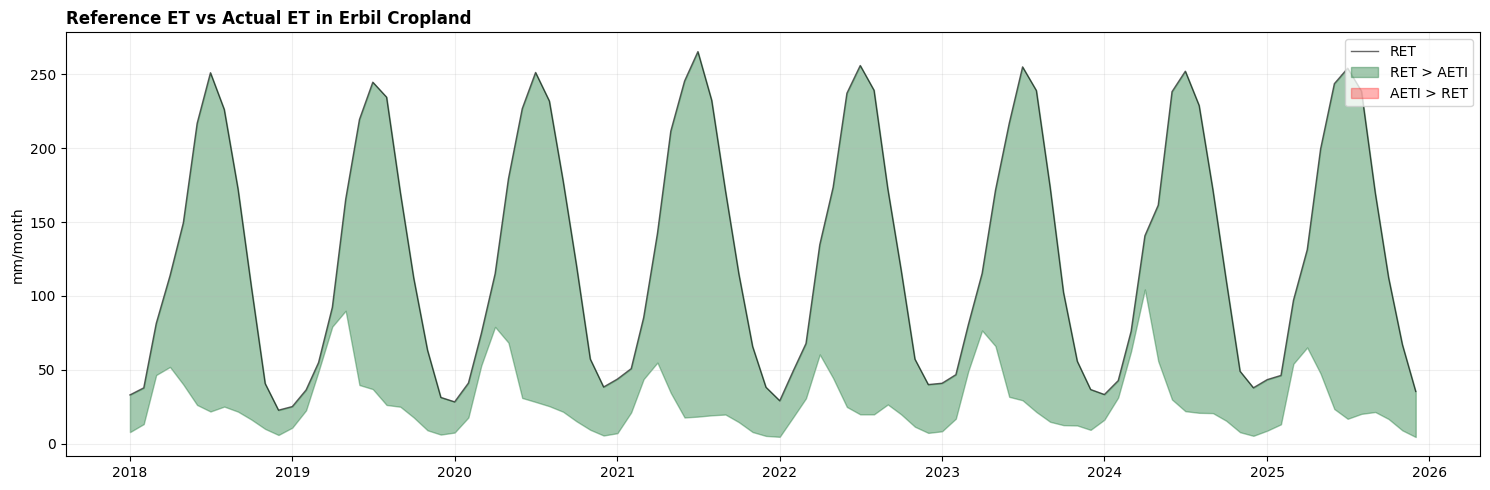

In [63]:
# =============================================================================
# RET vs AETI
# =============================================================================

fig, ax = plt.subplots(1, 1, figsize=(15, 5))

# --- RET vs AETI ---
ax.plot(
    df2.index,
    df2['RET_WaPOR'],
    color='black',
    linewidth=1,
    alpha=0.6,
    label='RET'
)

# Shade the area between RET and AETI
ax.fill_between(
    df2.index,
    df2['RET_WaPOR'],
    df2['AETI_WaPOR'],
    where=df2['RET_WaPOR'] >= df2['AETI_WaPOR'],
    color='#1b7837',
    alpha=0.4,
    label='RET > AETI'
)

# Shade the area where AETI exceeds RET
ax.fill_between(
    df2.index,
    df2['RET_WaPOR'],
    df2['AETI_WaPOR'],
    where=df2['RET_WaPOR'] < df2['AETI_WaPOR'],
    color='red',
    alpha=0.3,
    label='AETI > RET'
)

# Labels and formatting
ax.set_ylabel('mm/month')
ax.set_title(
    'Reference ET vs Actual ET in Erbil Cropland',
    fontweight='bold',
    loc='left'
)

ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

---

## 6. Seasonal analyses

To get a better grip on the different cropping seasons (summer and winter), we first investigate the seasonality through the mean monthly values.

     PCP_WaPOR  RET_WaPOR  AETI_WaPOR  NPP_WaPOR
Jan     118.88      34.55        8.84      12.58
Feb     132.41      43.88       19.22      25.75
Mar     146.00      77.20       48.48      60.81
Apr     117.78     123.19       71.42      84.15
May      54.86     176.53       55.79      42.02
Jun       3.64     230.65       28.00       5.68
Jul       1.02     253.82       24.11       1.56
Aug       1.27     233.96       22.22       1.41
Sep       1.77     172.40       21.37       3.22
Oct      13.98     112.11       15.99       5.37
Nov      73.98      56.99        9.54       5.85
Dec     108.54      35.01        6.09       7.04


<Axes: >

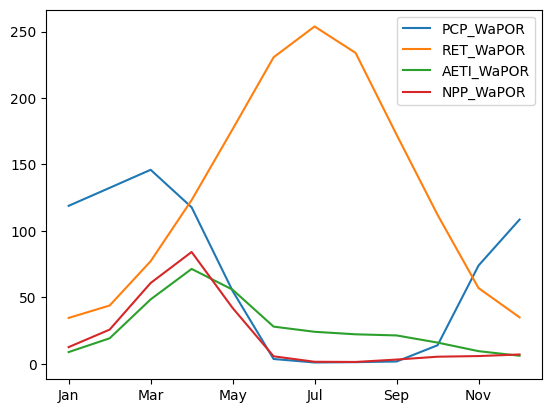

In [64]:
# =============================================================================
# MONTHLY CLIMATOLOGY
# =============================================================================

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Compute monthly climatology
df2_month = df2.groupby(df2.index.month).mean()
df2_month.index = month_names

print(df2_month.round(2))

df2_month.plot(legend=True)

Erbil has two cropping seasons, winter and summer. One of the seasons is rainfed and one is fully dependent on irrigation.

| Season | Months | Character |
|--------|--------|-----------|
| **Wet/Growing** | Nov – May | Rainfall arrives; crops grow; AETI peaks during spring |
| **Dry/Fallow** | Jun – Oct | Virtually no rain; high ET demand; irrigation critical |

We decompose the data by season to see which months drive annual variability.
Lets summarise the data for the winter season first (which start each year in November and ends the following year in May).

In [65]:
# =============================================================================
# AGGREGATE DATA FOR WINTER SEASON (NOVEMBER-MAY)
# =============================================================================

winter_season_data = [] # Initialize here to clear previous runs
# We want periods from Nov Y to May Y+1

start_year = df2.index.min().year
end_year = df2.index.max().year

# Loop through relevant years for the start of the season
for year in range(start_year, end_year):
    season_start = pd.Timestamp(f'{year}-11-01')
    season_end = pd.Timestamp(f'{year + 1}-05-31')

    # Check if the season is fully contained within the DataFrame's date range
    if season_start >= df2.index.min() and season_end <= df2.index.max():
        season_period_df = df2.loc[season_start:season_end]

        # Sum the values for the season
        season_sum = season_period_df.sum().to_dict()
        season_sum['Season'] = f'Nov {year} - May {year+1}'
        winter_season_data.append(season_sum)

# Create a DataFrame from the seasonal sums
df_winter_sums = pd.DataFrame(winter_season_data)

# Set Season as index and reorder columns for better readability
df_winter_sums = df_winter_sums.set_index('Season')
df_winter_sums = df_winter_sums[['PCP_WaPOR', 'RET_WaPOR', 'AETI_WaPOR', 'NPP_WaPOR']]

print("Seasonal Sums (Nov-May):")
display(df_winter_sums)

Seasonal Sums (Nov-May):


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
Season,,,,
Nov 2018 - May 2019,1315.85,437.34,266.91,324.22
Nov 2019 - May 2020,737.78,532.98,240.42,280.44
Nov 2020 - May 2021,535.96,629.37,175.71,155.69
Nov 2021 - May 2022,579.09,558.77,171.06,163.60
Nov 2022 - May 2023,577.95,551.98,235.44,264.78
Nov 2023 - May 2024,741.44,546.53,291.57,352.21
Nov 2024 - May 2025,466.98,604.08,201.23,179.72


Calculate the correlation between the different variables in the winter season. Do you notice that the correlation between PCP and the agricultural variables is much higher than when it is compared for annual values, indicating a more direct agricultural response to rainfall.

In [66]:
# =============================================================================
# CALCULATE CORRELATION OF DATA FOR WINTER SEASON (NOVEMBER-MAY)
# =============================================================================

corr_winter=df_winter_sums.corr()**2
print(corr_winter.round(2))

            PCP_WaPOR  RET_WaPOR  AETI_WaPOR  NPP_WaPOR
PCP_WaPOR        1.00       0.86        0.38       0.45
RET_WaPOR        0.86       1.00        0.43       0.53
AETI_WaPOR       0.38       0.43        1.00       0.98
NPP_WaPOR        0.45       0.53        0.98       1.00


Repeat analyses for the summer season (Jun-Oct) and answer the questions below.

In [67]:
# =============================================================================
# AGGREGATE DATA FOR SUMMER SEASON (JUN-OCT)
# =============================================================================

summer_season_data = [] # Initialize here to clear previous runs
# We want periods from Nov Y to May Y+1

start_year = df2.index.min().year
end_year = df2.index.max().year

# Loop through relevant years for the start of the season
for year in range(start_year, end_year):
    season_start = pd.Timestamp(f'{year}-06-01')
    season_end = pd.Timestamp(f'{year}-10-31')

    # Check if the season is fully contained within the DataFrame's date range
    if season_start >= df2.index.min() and season_end <= df2.index.max():
        season_period_df = df2.loc[season_start:season_end]

        # Sum the values for the season
        season_sum = season_period_df.sum().to_dict()
        season_sum['Season'] = f'Jun {year} - Oct {year}'
        summer_season_data.append(season_sum)

# Create a DataFrame from the seasonal sums
df_summer_sums = pd.DataFrame(summer_season_data)

# Set Season as index and reorder columns for better readability
df_summer_sums = df_summer_sums.set_index('Season')
df_summer_sums = df_summer_sums[['PCP_WaPOR', 'RET_WaPOR', 'AETI_WaPOR', 'NPP_WaPOR']]

print("Seasonal Sums (Nov-May):")
display(df_summer_sums)

Seasonal Sums (Nov-May):


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
Season,,,,
Jun 2018 - Oct 2018,52.17,973.10,110.80,14.46
Jun 2019 - Oct 2019,35.76,981.11,145.33,22.19
Jun 2020 - Oct 2020,7.40,1008.76,121.05,18.77
Jun 2021 - Oct 2021,19.52,1029.77,89.22,11.48
Jun 2022 - Oct 2022,9.17,1022.72,110.62,15.91
Jun 2023 - Oct 2023,22.73,987.25,109.59,19.17
Jun 2024 - Oct 2024,18.98,1001.80,108.66,18.51


Correlation Matrix — Summer Season (Jun-Oct):


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
PCP_WaPOR,1.000000,-0.792364,0.222717,-0.026673
RET_WaPOR,-0.792364,1.000000,-0.560204,-0.507754
AETI_WaPOR,0.222717,-0.560204,1.000000,0.856093
NPP_WaPOR,-0.026673,-0.507754,0.856093,1.000000


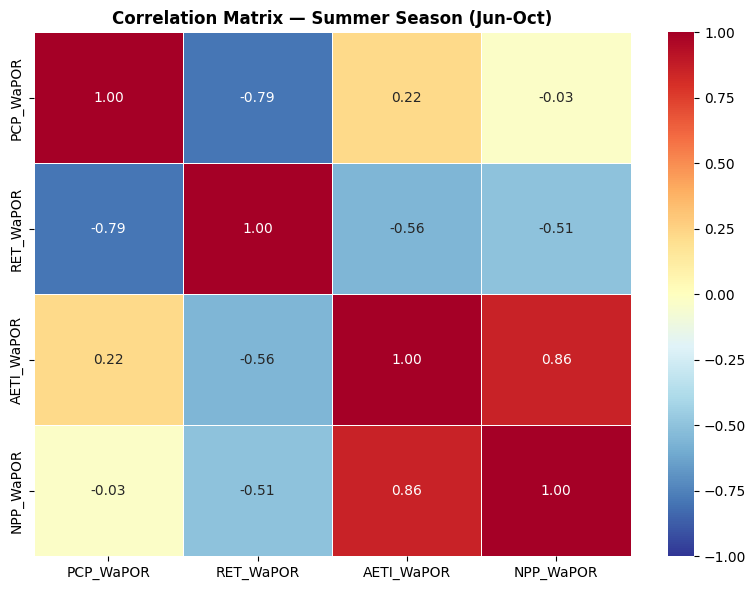

In [68]:
# =============================================================================
# CALCULATE CORRELATION OF DATA FOR SUMMER SEASON (JUN-OCT)
# =============================================================================

# Calculate Pearson correlation matrix
summer_correlation = df_summer_sums.corr(method='pearson')

# Display correlation matrix
print("Correlation Matrix — Summer Season (Jun-Oct):")
display(summer_correlation)

# Plot correlation matrix as a heatmap
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    summer_correlation,
    annot=True,
    cmap='RdYlBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    'Correlation Matrix — Summer Season (Jun-Oct)',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In which season does AETI and NPP have the highest correlation with precipitation?

---

Now plot the two timeseries into one plot.

In [69]:
# =============================================================================
# CALCULATE CORRELATIONS: SUMMER VS WINTER SEASONS
# =============================================================================

# Summer season correlation
summer_correlation = df_summer_sums.corr(method='pearson')

# Winter season correlation
winter_correlation = df_winter_sums.corr(method='pearson')

# Display summer correlations
print("SUMMER SEASON (JUN-OCT)")
display(summer_correlation)

# Display winter correlations
print("WINTER SEASON (NOV-MAY)")
display(winter_correlation)

# Compare correlations of PCP with AETI and NPP
seasonal_comparison = pd.DataFrame({
    'Summer (Jun-Oct)': summer_correlation.loc[
        ['AETI_WaPOR', 'NPP_WaPOR'], 'PCP_WaPOR'
    ],
    'Winter (Nov-May)': winter_correlation.loc[
        ['AETI_WaPOR', 'NPP_WaPOR'], 'PCP_WaPOR'
    ]
})

print("PCP CORRELATION WITH AETI AND NPP")
display(seasonal_comparison)

SUMMER SEASON (JUN-OCT)


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
PCP_WaPOR,1.000000,-0.792364,0.222717,-0.026673
RET_WaPOR,-0.792364,1.000000,-0.560204,-0.507754
AETI_WaPOR,0.222717,-0.560204,1.000000,0.856093
NPP_WaPOR,-0.026673,-0.507754,0.856093,1.000000


WINTER SEASON (NOV-MAY)


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
PCP_WaPOR,1.000000,-0.927481,0.612891,0.668581
RET_WaPOR,-0.927481,1.000000,-0.653530,-0.726027
AETI_WaPOR,0.612891,-0.653530,1.000000,0.987871
NPP_WaPOR,0.668581,-0.726027,0.987871,1.000000


PCP CORRELATION WITH AETI AND NPP


,Summer (Jun-Oct),Winter (Nov-May)
AETI_WaPOR,0.222717,0.612891
NPP_WaPOR,-0.026673,0.668581


In [71]:
# =============================================================================
# WET vs. DRY SEASON — ANNUAL COMPARISON
# =============================================================================

# Create copies of the seasonal datasets
df_summer_plot = df_summer_sums.copy()
df_winter_plot = df_winter_sums.copy()

# Extract the starting year from each season label
df_summer_plot['Year'] = (
    df_summer_plot.index.to_series()
    .str.extract(r'(\d{4})', expand=False)
    .astype(int)
    .values
)

df_winter_plot['Year'] = (
    df_winter_plot.index.to_series()
    .str.extract(r'(\d{4})', expand=False)
    .astype(int)
    .values
)

# Set Year as the index
df_summer_plot = df_summer_plot.set_index('Year')
df_winter_plot = df_winter_plot.set_index('Year')

# Display the datasets
print("SUMMER SEASON (JUN-OCT)")
display(df_summer_plot)

print("WINTER SEASON (NOV-MAY)")
display(df_winter_plot)

SUMMER SEASON (JUN-OCT)


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
Year,,,,
2018,52.17,973.10,110.80,14.46
2019,35.76,981.11,145.33,22.19
2020,7.40,1008.76,121.05,18.77
2021,19.52,1029.77,89.22,11.48
2022,9.17,1022.72,110.62,15.91
2023,22.73,987.25,109.59,19.17
2024,18.98,1001.80,108.66,18.51


WINTER SEASON (NOV-MAY)


,PCP_WaPOR,RET_WaPOR,AETI_WaPOR,NPP_WaPOR
Year,,,,
2018,1315.85,437.34,266.91,324.22
2019,737.78,532.98,240.42,280.44
2020,535.96,629.37,175.71,155.69
2021,579.09,558.77,171.06,163.60
2022,577.95,551.98,235.44,264.78
2023,741.44,546.53,291.57,352.21
2024,466.98,604.08,201.23,179.72


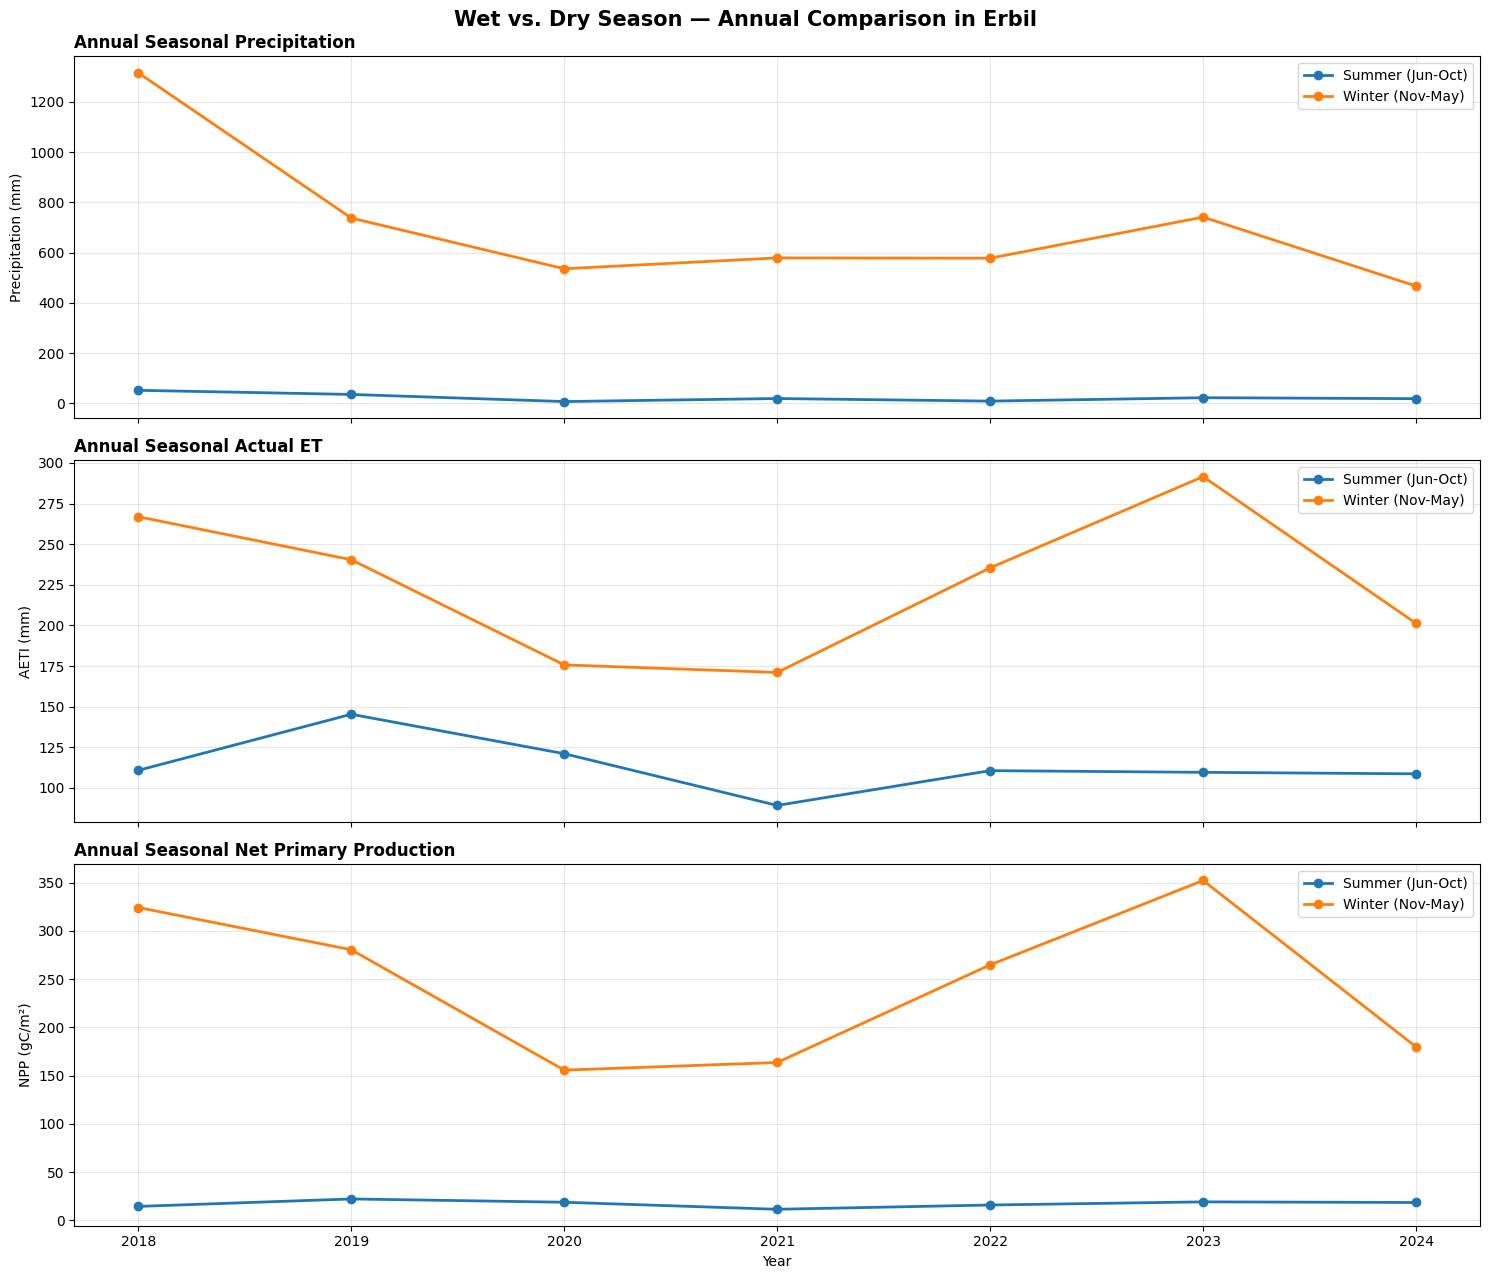

In [72]:
# =============================================================================
# WET vs. DRY SEASON — ANNUAL COMPARISON
# =============================================================================

fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

years = df_summer_plot.index

# --- 1. PRECIPITATION ---
axes[0].plot(
    years, df_summer_plot['PCP_WaPOR'],
    marker='o', linewidth=2, label='Summer (Jun-Oct)'
)

axes[0].plot(
    years, df_winter_plot['PCP_WaPOR'],
    marker='o', linewidth=2, label='Winter (Nov-May)'
)

axes[0].set_ylabel('Precipitation (mm)')
axes[0].set_title('Annual Seasonal Precipitation', loc='left', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)


# --- 2. ACTUAL EVAPOTRANSPIRATION ---
axes[1].plot(
    years, df_summer_plot['AETI_WaPOR'],
    marker='o', linewidth=2, label='Summer (Jun-Oct)'
)

axes[1].plot(
    years, df_winter_plot['AETI_WaPOR'],
    marker='o', linewidth=2, label='Winter (Nov-May)'
)

axes[1].set_ylabel('AETI (mm)')
axes[1].set_title('Annual Seasonal Actual ET', loc='left', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)


# --- 3. NET PRIMARY PRODUCTION ---
axes[2].plot(
    years, df_summer_plot['NPP_WaPOR'],
    marker='o', linewidth=2, label='Summer (Jun-Oct)'
)

axes[2].plot(
    years, df_winter_plot['NPP_WaPOR'],
    marker='o', linewidth=2, label='Winter (Nov-May)'
)

axes[2].set_ylabel('NPP (gC/m²)')
axes[2].set_xlabel('Year')
axes[2].set_title('Annual Seasonal Net Primary Production', loc='left', fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle(
    'Wet vs. Dry Season — Annual Comparison in Erbil',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

<details>
<summary> 🔎 HINT</summary>
    <img src="https://raw.githubusercontent.com/wateraccounting/WaPORMOOC/main/images/WetvsDry%20season-annual%20totals.png"
     height="600" width="auto" style="vertical-align:middle; margin-left:8px;">


The results show a much higher AETI and NPP in the winter season for cropland, despite the cold conditions. During the summer crops are only able to grow where irrigation is applied.

> 💡 If you want to investigate more about what influences the mean of agricultural water use and production in cropland in Erbil, we offer [Notebook 3.3](https://github.com/wateraccounting/WaPOR4Global/blob/main/3_Correlation_Analyses/Notebook_3.3_Estimating_irrigated_area_using_GEE.ipynb) where Google Earth Engine is used to estimate the irrigated area during the summer season.

---

## ➡️ 7. Visualising results

> Go to [Notebook 3.2 Visualising correlation analyses](https://github.com/wateraccounting/WaPOR4Global/blob/main/3_Correlation_Analyses/Notebook_3.2_Visualising_Correlation_Analyses.ipynb) to learn more about how to improve visualisation of the results.

---

### 📚 References

1. **FAO WaPOR**: https://wapor.apps.fao.org/
2. **Water Productivity**: Bastiaanssen, W.G.M. & Steduto, P. (2017). The water productivity score (WPS) at global and regional level.
---